# Minimal RLHF from scratch: a happy TinyStories GPT

A from-scratch, single-notebook reimplementation of the core RLHF loop:

1. **Pretrain** a tiny character-level GPT on [TinyStories](https://huggingface.co/datasets/roneneldan/TinyStories).
2. **Supervised fine-tune (SFT)** it on the subset of stories that VADER rates as positive.
3. **Reinforcement learning (RL)** with a vanilla policy gradient: sample stories, reward them with VADER
   sentiment, penalise drift from the frozen SFT model with a KL term, and push the policy toward happier text.



**Runtime modes.** `SMOKE = True` runs a few minutes on a laptop (MPS/CPU) with a 20k-story subset. `SMOKE = False` is the full run, meant for a single A100 on Gilbreth. By default `SMOKE`is on whenever CUDA is *not* available.

In [5]:
import os, math, copy, time, json
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# --- paths -------------------------------------------------------------------
PROJ = os.getcwd()                                   # run the notebook from the repo root
OUT = os.path.join(PROJ, "out"); os.makedirs(OUT, exist_ok=True)
# Optional: keep the ~2 GB dataset cache and the VADER lexicon inside the project instead of ~/.cache
# (handy on clusters with a small home quota). Just create the two folders; setup_gilbreth.sh does.
for var, folder in (("HF_HOME", "hf_cache"), ("NLTK_DATA", "nltk_data")):
    if os.path.isdir(os.path.join(PROJ, folder)):
        os.environ.setdefault(var, os.path.join(PROJ, folder))

device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
SMOKE  = os.environ.get("RLHF_SMOKE", str(not torch.cuda.is_available())).lower() in ("1", "true")
print(f"device={device}  SMOKE={SMOKE}  OUT={OUT}")

# --- one place for every knob -----------------------------------------------
CFG = dict(
    seed=42,
    # model (same size as the original "gpt-micro")
    block_size=64, n_layer=4, n_head=4, n_embd=128, dropout=0.1,
    # stage 1: pretrain
    pre_lr=5e-4, pre_batch=128, pre_epochs=1,
    # stage 2: SFT on positive stories (VADER compound > 0.05)
    sft_lr=1e-4, sft_batch=128, sft_epochs=2, positive_threshold=0.05,
    # stage 3: RL (vanilla policy gradient)
    rl_lr=1e-5, rl_batch=64, rl_iters=200, kl_beta=0.1, rl_top_k=30, rl_temperature=1.0,
    # three tiny improvements over the original; flip to False to reproduce it exactly
    action_mask=True,      # ignore loss on tokens after the first end-of-text token
    reward_baseline=True,  # subtract the batch-mean reward before the policy-gradient step
    stop_at_eot=True,      # score only the text before the first end-of-text token
    # bookkeeping
    weight_decay=0.1, grad_clip=1.0, log_every=500, sample_every=2000,
)
if SMOKE:
    CFG.update(n_train=20_000, n_val=2_000, pre_steps=300, pre_batch=64, sft_steps=100, sft_batch=64,
               rl_iters=10, rl_batch=16, log_every=50, sample_every=150)

torch.manual_seed(CFG["seed"]); np.random.seed(CFG["seed"])

device=cuda  SMOKE=False  OUT=<project>/out


## 1. Data: TinyStories as one `uint8` tensor

Each story becomes one training row of `block_size + 1 = 65` tokens: an end-of-text marker `⏎` (acting as
"beginning of story") followed by the first 64 characters. Shorter stories are padded with `␣`.

The row is split into an input `x = row[:-1]` and a target `y = row[1:]`: the model at position *t* sees
characters `0..t` and must predict character `t+1`. That one-character shift *is* language modelling.
Padding positions get target `-1`, which cross-entropy ignores.

A character vocabulary is small (< 256 symbols), so the full 2.1M-row training set is ~140 MB as `uint8`
and lives on the GPU. Batches are random row indices; there is no `Dataset` or `DataLoader`.

In [6]:
from datasets import load_dataset

if SMOKE:   # stream just the head of the files; no 2 GB download on a laptop
    train_texts = [r["text"] for r in load_dataset("roneneldan/TinyStories", split="train", streaming=True).take(CFG["n_train"])]
    val_texts   = [r["text"] for r in load_dataset("roneneldan/TinyStories", split="validation", streaming=True).take(CFG["n_val"])]
else:
    ds = load_dataset("roneneldan/TinyStories")
    train_texts, val_texts = ds["train"]["text"], ds["validation"]["text"]
print(f"{len(train_texts):,} train stories, {len(val_texts):,} validation stories")
print(train_texts[0][:300], "...")

2,119,719 train stories, 21,990 validation stories
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and  ...


In [7]:
EOT_CH, PAD_CH = "⏎", "␣"          # end-of-text (also used as the prompt) and padding
T = CFG["block_size"] + 1

def to_codepoints(texts, chunk=200_000):
    # (EOT + text) truncated / padded to T chars -> (N, T) array of unicode code points. Vectorised via utf-32.
    parts = []
    for i in range(0, len(texts), chunk):
        s = "".join((EOT_CH + t)[:T].ljust(T, PAD_CH) for t in texts[i:i + chunk])
        parts.append(np.frombuffer(s.encode("utf-32-le"), dtype=np.uint32).reshape(-1, T))
    return np.concatenate(parts)

train_cp, val_cp = to_codepoints(train_texts), to_codepoints(val_texts)

# vocabulary = every character in the rows (train + val) plus the two specials, sorted
chars = sorted({chr(c) for c in np.concatenate([np.unique(train_cp), np.unique(val_cp)])} | {EOT_CH, PAD_CH})
assert len(chars) < 256, "uint8 storage assumes a small character vocabulary"
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}
VOCAB, EOT, PAD = len(chars), stoi[EOT_CH], stoi[PAD_CH]

lut = np.zeros(0x110000, dtype=np.uint8)              # code point -> token id
for ch, i in stoi.items(): lut[ord(ch)] = i
train_data = torch.from_numpy(lut[train_cp]).to(device)   # (N, 65) uint8, on the GPU
val_data   = torch.from_numpy(lut[val_cp]).to(device)
del train_cp, val_cp

def encode(s):                 return [stoi[c] for c in s]
def decode(ids, stop_at_eot=True):
    ids = [int(i) for i in ids]
    if ids and ids[0] == EOT: ids = ids[1:]                         # drop the leading "beginning of story"
    if stop_at_eot and EOT in ids: ids = ids[:ids.index(EOT)]       # cut at the first real end-of-text
    return "".join(itos[i] for i in ids if i not in (PAD, EOT))

print(f"vocab={VOCAB}  EOT={EOT}  PAD={PAD}  train_data={tuple(train_data.shape)} {train_data.dtype}")
print("row 0 :", repr(decode(train_data[0])))

vocab=114  EOT=112  PAD=113  train_data=(2119719, 65) torch.uint8
row 0 : 'One day, a little girl named Lily found a needle in her room. Sh'


In [8]:
# VADER sentiment for every training story. Used (a) to pick the SFT subset and (b) as the RL reward.
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
try:    SentimentIntensityAnalyzer()
except LookupError: nltk.download("vader_lexicon")
sia = SentimentIntensityAnalyzer()
def vader(text):                       # scalar in [-1, 1]; a named def (not a lambda) so worker processes can pickle it
    return sia.polarity_scores(text)["compound"]

mask_path = f"{OUT}/positive_mask_{len(train_texts)}.pt"
if os.path.exists(mask_path):
    scores = torch.load(mask_path)
else:
    t0 = time.time()
    if len(train_texts) > 100_000:          # ~1 ms per story; fan out over the CPU cores
        from concurrent.futures import ProcessPoolExecutor
        import multiprocessing as mp
        with ProcessPoolExecutor(mp_context=mp.get_context("fork")) as ex:
            scores = torch.tensor(list(ex.map(vader, train_texts, chunksize=5_000)))
    else:
        scores = torch.tensor([vader(t) for t in train_texts])
    torch.save(scores, mask_path)
    print(f"scored {len(scores):,} stories in {time.time() - t0:.0f}s")

positive = (scores > CFG["positive_threshold"]).to(device)
sft_data = train_data[positive]
print(f"{int(positive.sum()):,} / {len(scores):,} stories are positive ({positive.float().mean():.1%});  "
      f"mean compound = {scores.mean():.3f}")

scored 2,119,719 stories in 55s
1,911,657 / 2,119,719 stories are positive (90.2%);  mean compound = 0.776


## 2. Model: a small GPT

Standard decoder-only transformer: token + position embeddings, `n_layer` pre-LayerNorm blocks (causal
self-attention then a 4x MLP), a final LayerNorm and a linear head over the vocabulary.
Causal masking comes from `F.scaled_dot_product_attention(..., is_causal=True)`, which uses the fused flash
kernel on an A100. No padding mask is needed: padding only ever appears *after* the real characters, and a
causal model never looks ahead, so real tokens never attend to padding.

Three methods matter for RLHF:

- `forward(x, y)` returns logits and the next-token cross-entropy (ignoring `y == -1`).
- `log_probs(x, y)` returns $\log \pi_\theta(y_t \mid x_{\le t})$ for every position: the probability the
  model assigned to the token that was actually produced. RL differentiates *this*.
- `generate(...)` samples autoregressively with temperature and top-k.

In [9]:
class CausalSelfAttention(nn.Module):
    def __init__(s, n_embd, n_head, dropout):
        super().__init__()
        s.n_head, s.dropout = n_head, dropout
        s.qkv  = nn.Linear(n_embd, 3 * n_embd)
        s.proj = nn.Linear(n_embd, n_embd)
        s.resid_drop = nn.Dropout(dropout)

    def forward(s, x):
        B, T, C = x.shape
        q, k, v = s.qkv(x).split(C, dim=2)
        q, k, v = (t.view(B, T, s.n_head, C // s.n_head).transpose(1, 2) for t in (q, k, v))  # (B, nh, T, hd)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True, dropout_p=s.dropout if s.training else 0.0)
        return s.resid_drop(s.proj(y.transpose(1, 2).reshape(B, T, C)))

class Block(nn.Module):
    def __init__(s, n_embd, n_head, dropout):
        super().__init__()
        s.ln1, s.attn = nn.LayerNorm(n_embd), CausalSelfAttention(n_embd, n_head, dropout)
        s.ln2 = nn.LayerNorm(n_embd)
        s.mlp = nn.Sequential(nn.Linear(n_embd, 4 * n_embd), nn.GELU(), nn.Linear(4 * n_embd, n_embd), nn.Dropout(dropout))

    def forward(s, x):
        x = x + s.attn(s.ln1(x))
        return x + s.mlp(s.ln2(x))

class GPT(nn.Module):
    def __init__(s, vocab_size, block_size, n_layer, n_head, n_embd, dropout):
        super().__init__()
        s.block_size = block_size
        s.tok_emb = nn.Embedding(vocab_size, n_embd)
        s.pos_emb = nn.Embedding(block_size, n_embd)
        s.drop    = nn.Dropout(dropout)
        s.blocks  = nn.ModuleList(Block(n_embd, n_head, dropout) for _ in range(n_layer))
        s.ln_f    = nn.LayerNorm(n_embd)
        s.head    = nn.Linear(n_embd, vocab_size, bias=False)
        s.apply(s._init)

    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, std=0.02)
            if getattr(m, "bias", None) is not None: nn.init.zeros_(m.bias)

    def forward(s, x, y=None):
        B, T = x.shape
        assert T <= s.block_size
        h = s.drop(s.tok_emb(x) + s.pos_emb(torch.arange(T, device=x.device)))
        for blk in s.blocks: h = blk(h)
        logits = s.head(s.ln_f(h))                                           # (B, T, V)
        loss = None if y is None else F.cross_entropy(logits.view(-1, logits.size(-1)), y.view(-1), ignore_index=-1)
        return logits, loss

    def log_probs(s, x, y):
        # log pi(y_t | x_<=t) for every position -> (B, T)
        logits, _ = s(x)
        return F.log_softmax(logits.float(), dim=-1).gather(-1, y.unsqueeze(-1)).squeeze(-1)

    @torch.no_grad()
    def generate(s, idx, max_new_tokens, temperature=1.0, top_k=None):
        for _ in range(max_new_tokens):
            logits, _ = s(idx[:, -s.block_size:])
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                kth = torch.topk(logits, top_k).values[:, -1, None]
                logits = logits.masked_fill(logits < kth, float("-inf"))
            nxt = torch.multinomial(F.softmax(logits, dim=-1), num_samples=1)
            idx = torch.cat([idx, nxt], dim=1)
        return idx

    def configure_optimizer(s, lr, weight_decay):
        decay    = [p for p in s.parameters() if p.dim() >= 2]      # matrices: weight decay
        no_decay = [p for p in s.parameters() if p.dim() <  2]      # biases, LayerNorm: none
        return torch.optim.AdamW([{"params": decay, "weight_decay": weight_decay},
                                  {"params": no_decay, "weight_decay": 0.0}], lr=lr, betas=(0.9, 0.95))

def new_model():
    return GPT(VOCAB, CFG["block_size"], CFG["n_layer"], CFG["n_head"], CFG["n_embd"], CFG["dropout"]).to(device)

model = new_model()
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f}M parameters")

0.83M parameters


## 3. Training loop (shared by pretraining and SFT)

A ~30-line loop: sample a random batch of rows from the tensor, AdamW step with gradient clipping, bf16
autocast on CUDA, validation loss every `log_every` steps and a sample story every `sample_every` steps.
Loss is in nats per character; `ln(vocab) ≈ 4.6` is the uniform-guess baseline.

In [10]:
def get_batch(data, batch_size):
    idx = torch.randint(len(data), (batch_size,), device=data.device)
    x, y = data[idx, :-1].long(), data[idx, 1:].long()
    y[y == PAD] = -1                                 # padding is never a prediction target
    return x, y

@torch.no_grad()
def estimate_loss(model, data, batches=20, batch_size=256):
    model.eval()
    loss = sum(model(*get_batch(data, batch_size))[1].item() for _ in range(batches)) / batches
    model.train(); return loss

@torch.no_grad()
def sample(model, prompt=EOT_CH + "Once upon a time, ", n=1, max_new_tokens=None, top_k=20, temperature=1.0):
    model.eval()
    x = torch.tensor([encode(prompt)] * n, device=device)
    out = model.generate(x, max_new_tokens or CFG["block_size"] - len(prompt) + 1, temperature, top_k)
    model.train()
    return [prompt[1:] + decode(row[len(prompt):]) for row in out]

autocast = torch.autocast("cuda", dtype=torch.bfloat16) if device == "cuda" else torch.autocast("cpu", enabled=False)

def train(model, data, val, *, lr, steps, batch_size, tag):
    opt = model.configure_optimizer(lr, CFG["weight_decay"])
    hist = {"step": [], "train": [], "val": []}
    model.train(); t0 = time.time()
    for step in range(1, steps + 1):
        x, y = get_batch(data, batch_size)
        with autocast:
            _, loss = model(x, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
        opt.step(); opt.zero_grad(set_to_none=True)
        if step % CFG["log_every"] == 0 or step == steps:
            vl = estimate_loss(model, val)
            hist["step"].append(step); hist["train"].append(loss.item()); hist["val"].append(vl)
            print(f"[{tag}] step {step:>6}/{steps}  train {loss.item():.3f}  val {vl:.3f}  ({time.time() - t0:.0f}s)")
        if step % CFG["sample_every"] == 0:
            print("   sample:", repr(sample(model)[0]))
    return hist

def plot_loss(hist, title, fname):
    plt.figure(figsize=(6, 3.5)); plt.plot(hist["step"], hist["train"], label="train"); plt.plot(hist["step"], hist["val"], label="val")
    plt.xlabel("step"); plt.ylabel("loss (nats/char)"); plt.title(title); plt.legend(); plt.grid(alpha=.3)
    plt.tight_layout(); plt.savefig(f"{OUT}/{fname}", dpi=120); plt.show()

def save(model, name):
    torch.save({"model": model.state_dict(), "chars": chars, "cfg": CFG}, f"{OUT}/{name}")
    print("saved", f"{OUT}/{name}")

def load(name):
    m = new_model(); m.load_state_dict(torch.load(f"{OUT}/{name}", map_location=device)["model"]); return m.eval()

## 4. Stage 1: pretraining

One pass over the training rows (`steps = N / batch_size`). The model only learns to continue stories;
it has no notion of sentiment yet.

[pretrain] step    500/16560  train 0.752  val 0.690  (38s)
[pretrain] step   1000/16560  train 0.656  val 0.563  (41s)
[pretrain] step   1500/16560  train 0.533  val 0.507  (45s)
[pretrain] step   2000/16560  train 0.486  val 0.464  (49s)
   sample: 'Once upon a time, in a small house, there was a little girl name'
[pretrain] step   2500/16560  train 0.441  val 0.448  (56s)
[pretrain] step   3000/16560  train 0.464  val 0.432  (59s)
[pretrain] step   3500/16560  train 0.467  val 0.410  (63s)
[pretrain] step   4000/16560  train 0.434  val 0.409  (67s)
   sample: 'Once upon a time, there was a bald kid named Timmy. Timmy loved '
[pretrain] step   4500/16560  train 0.494  val 0.411  (71s)
[pretrain] step   5000/16560  train 0.448  val 0.404  (75s)
[pretrain] step   5500/16560  train 0.410  val 0.391  (78s)
[pretrain] step   6000/16560  train 0.434  val 0.394  (82s)
   sample: 'Once upon a time, there was a little girl named Lily. She lived '
[pretrain] step   6500/16560  train 0.442  val

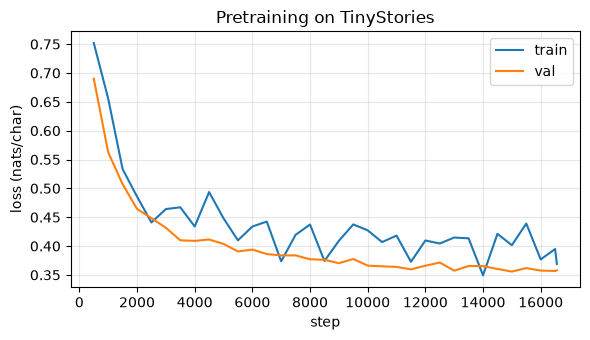

• Once upon a time, there was an elderly lady who lived in a hole.
• Once upon a time, there was a beautiful man who lived in a truck
• Once upon a time, there was a farmer who lived in a clever tall 


In [11]:
pre_steps = CFG.get("pre_steps") or CFG["pre_epochs"] * len(train_data) // CFG["pre_batch"]
hist_pre = train(model, train_data, val_data, lr=CFG["pre_lr"], steps=pre_steps, batch_size=CFG["pre_batch"], tag="pretrain")
save(model, "pretrained.pt")
plot_loss(hist_pre, "Pretraining on TinyStories", "pretrain.png")
for s in sample(model, n=3): print("•", s)

## 5. Stage 2: supervised fine-tuning on positive stories

Same loop, same loss, smaller learning rate, but the data is now only the rows VADER scored above
`positive_threshold`. This is "RLHF step 1" in the InstructGPT recipe: imitate demonstrations of the
behaviour we want. The mean VADER score of sampled stories after SFT is the baseline RL has to beat.

[sft] step    500/29869  train 0.362  val 0.343  (4s)
[sft] step   1000/29869  train 0.337  val 0.351  (8s)
[sft] step   1500/29869  train 0.342  val 0.348  (11s)
[sft] step   2000/29869  train 0.376  val 0.342  (15s)
   sample: 'Once upon a time, there was a little girl named Lily. She loved '
[sft] step   2500/29869  train 0.357  val 0.341  (19s)
[sft] step   3000/29869  train 0.370  val 0.342  (23s)
[sft] step   3500/29869  train 0.377  val 0.342  (27s)
[sft] step   4000/29869  train 0.372  val 0.342  (30s)
   sample: 'Once upon a time, there was a big bear named Benny. Benny loved '
[sft] step   4500/29869  train 0.332  val 0.345  (34s)
[sft] step   5000/29869  train 0.331  val 0.342  (38s)
[sft] step   5500/29869  train 0.351  val 0.340  (42s)
[sft] step   6000/29869  train 0.343  val 0.341  (46s)
   sample: 'Once upon a time, there was a little girl named Lily. One day, L'
[sft] step   6500/29869  train 0.346  val 0.342  (50s)
[sft] step   7000/29869  train 0.348  val 0.342  (53s

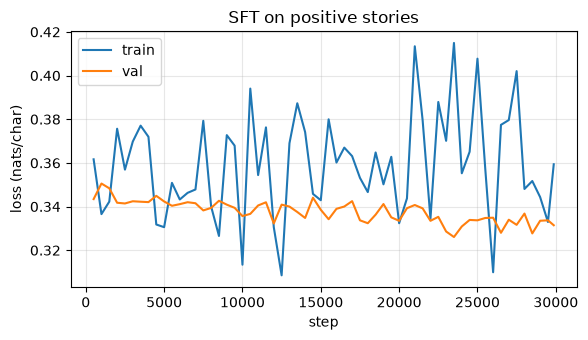

mean VADER of 64 SFT samples: 0.292
• Once upon a time, there was a prince who wore a special truck. H
• Once upon a time, there was a little girl named Sue. Sue loved t
• Once upon a time, there was a little boy named Timmy. He loved t


In [12]:
sft_steps = CFG.get("sft_steps") or CFG["sft_epochs"] * len(sft_data) // CFG["sft_batch"]
hist_sft = train(model, sft_data, val_data, lr=CFG["sft_lr"], steps=sft_steps, batch_size=CFG["sft_batch"], tag="sft")
save(model, "sft.pt")
plot_loss(hist_sft, "SFT on positive stories", "sft.png")

def mean_sentiment(model, n=64):
    prompt = torch.full((n, 1), EOT, dtype=torch.long, device=device)
    out = model.generate(prompt, CFG["block_size"], CFG["rl_temperature"], CFG["rl_top_k"])
    return float(np.mean([vader(decode(row)) for row in out]))

model.eval(); print(f"mean VADER of {64} SFT samples: {mean_sentiment(model):.3f}"); model.train()
for s in sample(model, n=3): print("•", s)

## 6. Stage 3: RL with a vanilla policy gradient

Each iteration:

1. **Sample** a batch of stories from the current policy $\pi_\theta$, starting from the single token `⏎`.
2. **Reward** each story with VADER's compound score $R \in [-1, 1]$ (one number per story).
3. **Reference log-probs**: how likely the frozen SFT model $\pi_{\text{ref}}$ finds the same tokens.
4. **Policy log-probs** $\log \pi_\theta(a_t)$ for every generated token, *with* gradients.
5. **KL estimate** per token: $\log \pi_\theta(a_t) - \log \pi_{\text{ref}}(a_t)$. Its expectation under
   $\pi_\theta$ is exactly $\mathrm{KL}(\pi_\theta \,\|\, \pi_{\text{ref}})$; a single sample is a noisy but
   unbiased estimate.
6. **Score** $s_t = R - \beta\,\mathrm{KL}_t$, **detached**: it is a weight on the gradient, not something
   to differentiate through.
7. **Loss** $-\,\mathrm{mean}_t\big(s_t \cdot \log \pi_\theta(a_t)\big)$. Minimising it raises the
   probability of tokens that led to high reward and lowers it for tokens the reference model would not
   have produced.

Three small, switchable improvements over the original implementation:

- `action_mask`: tokens after the first end-of-text are not real actions, so they get no gradient.
- `reward_baseline`: use $R - \bar R$ instead of $R$. The gradient's expectation is unchanged, its variance drops.
- `stop_at_eot`: VADER only sees the text before end-of-text, matching what a reader would see.

Dropout is switched off for this stage (`model.eval()`; gradients still flow). With dropout on, the policy and the
frozen reference would disagree even with identical weights, so the "KL" at iteration 0 would be noise rather than 0.

In [13]:
ref = copy.deepcopy(model).eval().requires_grad_(False)         # frozen SFT model
model.eval()   # dropout OFF for RL: eval mode still tracks gradients, and the KL estimate starts at exactly 0
opt = torch.optim.AdamW(model.parameters(), lr=CFG["rl_lr"], betas=(0.9, 0.95))
prompt = torch.full((CFG["rl_batch"], 1), EOT, dtype=torch.long, device=device)

def reward(tokens):                                     # (B, T) -> (B,)
    return torch.tensor([vader(decode(row, stop_at_eot=CFG["stop_at_eot"])) for row in tokens], device=device)

def action_mask(y):                                     # 1 for tokens up to and including the first EOT
    is_eot = (y == EOT).long()
    return ((is_eot.cumsum(1) - is_eot) == 0).float()

hist_rl = {"reward": [], "kl": []}
t0 = time.time()
for it in range(CFG["rl_iters"]):
    with torch.no_grad():
        comp = model.generate(prompt, CFG["block_size"], CFG["rl_temperature"], CFG["rl_top_k"])   # (B, 65)
        x, y = comp[:, :-1], comp[:, 1:]
        R = reward(comp)                                                                            # (B,)
        ref_lp = ref.log_probs(x, y)                                                                # (B, 64)

    lp   = model.log_probs(x, y)                            # (B, 64), with grad
    kl   = lp - ref_lp                                      # per-token KL estimate
    mask = action_mask(y) if CFG["action_mask"] else torch.ones_like(lp)
    adv  = R - R.mean() if CFG["reward_baseline"] else R
    score = (adv[:, None] - CFG["kl_beta"] * kl).detach()
    loss = -(score * lp * mask).sum() / mask.sum()

    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
    opt.step(); opt.zero_grad(set_to_none=True)

    kl_mean = ((kl * mask).sum() / mask.sum()).item()
    hist_rl["reward"].append(R.mean().item()); hist_rl["kl"].append(kl_mean)
    if it % 10 == 0 or it == CFG["rl_iters"] - 1:
        print(f"[rl] iter {it:>4}  reward {R.mean():.3f}  kl {kl_mean:.4f}  loss {loss.item():.4f}  ({time.time() - t0:.0f}s)")
    if it % 50 == 0:
        print("   sample:", repr(decode(comp[0])))

save(model, "rl.pt")

[rl] iter    0  reward 0.295  kl 0.0000  loss 0.0077  (15s)
   sample: 'Once upon a time, there was a little girl named Lily. She loved '
[rl] iter   10  reward 0.331  kl 0.0005  loss -0.0066  (17s)
[rl] iter   20  reward 0.342  kl 0.0004  loss -0.0083  (18s)
[rl] iter   30  reward 0.366  kl 0.0006  loss -0.0156  (20s)
[rl] iter   40  reward 0.406  kl 0.0019  loss -0.0259  (21s)
[rl] iter   50  reward 0.392  kl 0.0012  loss -0.0129  (23s)
   sample: 'Once upon a time, there was a little girl named Lily. She loved '
[rl] iter   60  reward 0.439  kl 0.0030  loss -0.0143  (24s)
[rl] iter   70  reward 0.427  kl 0.0019  loss -0.0101  (26s)
[rl] iter   80  reward 0.481  kl 0.0029  loss -0.0060  (27s)
[rl] iter   90  reward 0.469  kl 0.0038  loss -0.0131  (29s)
[rl] iter  100  reward 0.533  kl 0.0071  loss -0.0127  (30s)
   sample: 'Once upon a time, there lived a blue soup on a shelf. One day, t'
[rl] iter  110  reward 0.517  kl 0.0058  loss -0.0161  (32s)
[rl] iter  120  reward 0.560  kl 0.

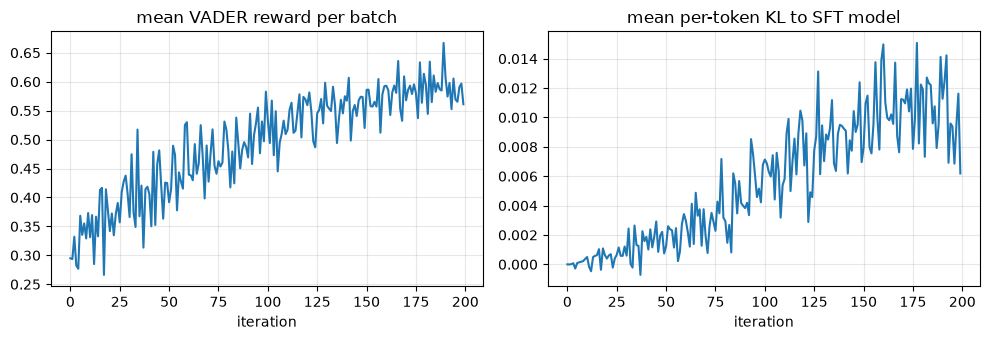

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(hist_rl["reward"]); ax[0].set_title("mean VADER reward per batch"); ax[0].set_xlabel("iteration"); ax[0].grid(alpha=.3)
ax[1].plot(hist_rl["kl"]);     ax[1].set_title("mean per-token KL to SFT model"); ax[1].set_xlabel("iteration"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/rl.png", dpi=120); plt.show()

## 7. Pretrained vs SFT vs RL

Same prompt, same sampling settings, same random seed for each model. VADER compound in brackets.
Expected ordering of mean sentiment: pretrained < SFT < RL, with RL text still reading like TinyStories
(if it degenerates into "happy happy happy", raise `kl_beta`).

In [15]:
models = {name: load(f"{name}.pt") for name in ("pretrained", "sft", "rl")}
n_show, n_score = 5, 64
for name, m in models.items():
    torch.manual_seed(CFG["seed"])
    print(f"\n=== {name}  (mean VADER over {n_score} samples: {mean_sentiment(m, n_score):.3f}) ===")
    torch.manual_seed(CFG["seed"])
    for s in sample(m, n=n_show, top_k=CFG["rl_top_k"]):
        print(f"[{vader(s):+.2f}] {s}")


=== pretrained  (mean VADER over 64 samples: 0.329) ===
[+0.00] Once upon a time, there was a little boy named Jimmy. He was ver
[+0.60] Once upon a time, there was a kid named Timmy. Timmy loved to pl
[+0.82] Once upon a time, there was a little happy sheep. The sheat love
[+0.60] Once upon a time, there was a girl named Lily. Lily loved to kic
[+0.78] Once upon a time, there was a tiny car named Hope. Hoop loved to

=== sft  (mean VADER over 64 samples: 0.322) ===
[+0.00] Once upon a time, there was a little boy named Jimmy. He was thr
[+0.60] Once upon a time, there was a kid named Timmy. Timmy loved to pl
[+0.00] Once upon a time, there was a little house with a lot of fur and
[+0.62] Once upon a time, there was a great cat and a sheep. They lived 
[+0.00] Once upon a time, there was a tiny girl called Emma. Emma was ve

=== rl  (mean VADER over 64 samples: 0.565) ===
[+0.60] Once upon a time, there was a little boy named Jack. He loved to
[+0.60] Once upon a time, there was a kid